In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [22]:
cpi=pd.read_csv("stock_market/data/cpi.csv")
unrate=pd.read_csv("stock_market/data/UNRATE.csv")
fedfunds=pd.read_csv("stock_market/data/DFF.csv")
gdp=pd.read_csv("stock_market/data/gdp.csv")
sp500=pd.read_csv("stock_market/data/s&p.csv")

sp500.head()

,Date,SP500,Dividend,Earnings,Consumer Price Index,Long Interest Rate,Real Price,Real Dividend,Real Earnings,PE10
0,1871-01-01,4.44,0.26,0.4,12.46,5.32,109.05,6.39,9.82,0.0
1,1871-02-01,4.50,0.26,0.4,12.84,5.32,107.25,6.20,9.53,0.0
2,1871-03-01,4.61,0.26,0.4,13.03,5.33,108.27,6.11,9.39,0.0
3,1871-04-01,4.74,0.26,0.4,12.56,5.33,115.54,6.34,9.75,0.0
4,1871-05-01,4.86,0.26,0.4,12.27,5.33,121.22,6.48,9.98,0.0


In [16]:
import os

print(os.listdir("stock_market/data"))


['cpi.csv', '.DS_Store', 's&p.csv', 'DFF.csv', 'UNRATE.csv', 'gdp.csv']


In [23]:
print("CPI columns:", cpi.columns)
print(cpi.info())

print("GDP columns:", gdp.columns)
print(gdp.info())

print("S&P 500 columns:", sp500.columns)
print(sp500.info())

CPI columns: Index(['observation_date', 'CPALTT01USM657N'], dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 171 entries, 0 to 170
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  171 non-null    str    
 1   CPALTT01USM657N   171 non-null    float64
dtypes: float64(1), str(1)
memory usage: 2.8 KB
None
GDP columns: Index(['observation_date', 'NGDPSAXDCUSQ'], dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 57 entries, 0 to 56
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  57 non-null     str    
 1   NGDPSAXDCUSQ      57 non-null     float64
dtypes: float64(1), str(1)
memory usage: 1.0 KB
None
S&P 500 columns: Index(['Date', 'SP500', 'Dividend', 'Earnings', 'Consumer Price Index',
       'Long Interest Rate', 'Real Price', 'Real Dividend', 'Real Earnings',
       'PE10'],
      dty

In [24]:
cpi["observation_date"] = pd.to_datetime(cpi["observation_date"])
unrate["observation_date"] = pd.to_datetime(unrate["observation_date"])
fedfunds["observation_date"] = pd.to_datetime(fedfunds["observation_date"])
gdp["observation_date"] = pd.to_datetime(gdp["observation_date"])
sp500["Date"] = pd.to_datetime(sp500["Date"])

In [25]:
print("CPI:", cpi["observation_date"].min(), "~", cpi["observation_date"].max())
print("Unemployment:", unrate["observation_date"].min(), "~", unrate["observation_date"].max())
print("Fed Funds:", fedfunds["observation_date"].min(), "~", fedfunds["observation_date"].max())
print("GDP:", gdp["observation_date"].min(), "~", gdp["observation_date"].max())
print("S&P 500:", sp500["Date"].min(), "~", sp500["Date"].max())

CPI: 2010-01-01 00:00:00 ~ 2024-03-01 00:00:00
Unemployment: 2010-01-01 00:00:00 ~ 2024-03-01 00:00:00
Fed Funds: 2010-01-01 00:00:00 ~ 2024-03-01 00:00:00
GDP: 2010-01-01 00:00:00 ~ 2024-01-01 00:00:00
S&P 500: 1871-01-01 00:00:00 ~ 2026-09-01 00:00:00


In [26]:
sp500 = sp500[
    (sp500["Date"] >= "2010-01-01") &
    (sp500["Date"] <= "2024-03-01")
]

print(sp500.head())
print(sp500.tail())

           Date    SP500   Dividend   Earnings  Consumer Price Index  \
1668 2010-01-01  1123.58  22.240000  54.290000                216.69   
1669 2010-02-01  1089.16  22.070000  57.610000                216.74   
1670 2010-03-01  1152.05  21.900000  60.930000                217.63   
1671 2010-04-01  1197.32  21.946667  62.986667                218.01   
1672 2010-05-01  1125.06  21.993333  65.043333                218.18   

      Long Interest Rate  Real Price  Real Dividend  Real Earnings   PE10  
1668                3.73     1587.35          31.42          76.70  20.53  
1669                3.69     1538.34          31.17          81.37  19.92  
1670                3.73     1620.51          30.81          85.71  21.00  
1671                3.85     1681.27          30.82          88.45  21.80  
1672                3.42     1578.58          30.86          91.26  20.48  
           Date    SP500  Dividend  Earnings  Consumer Price Index  \
1834 2023-11-01  4460.06       0.0       

In [ ]:
# changing daily DFF to monthly average DFF

fedfunds["observation_date"] = pd.to_datetime(fedfunds["observation_date"])

fedfunds["month"] = fedfunds["observation_date"].dt.to_period("M")

fedfunds_monthly = fedfunds.groupby("month")["DFF"].mean().reset_index()

print(fedfunds_monthly.head())
print(fedfunds_monthly.tail())


fedfunds_monthly["observation_date"] = (
    fedfunds_monthly["month"].dt.to_timestamp()
)

print(fedfunds_monthly.head())

     month       DFF
0  2010-01  0.110000
1  2010-02  0.126429
2  2010-03  0.164516
3  2010-04  0.198333
4  2010-05  0.200645
       month   DFF
166  2023-11  5.33
167  2023-12  5.33
168  2024-01  5.33
169  2024-02  5.33
170  2024-03  5.33
     month       DFF observation_date
0  2010-01  0.110000       2010-01-01
1  2010-02  0.126429       2010-02-01
2  2010-03  0.164516       2010-03-01
3  2010-04  0.198333       2010-04-01
4  2010-05  0.200645       2010-05-01


In [29]:
print(gdp.head())
print(gdp.tail())

  observation_date  NGDPSAXDCUSQ
0       2010-01-01     3691152.5
1       2010-04-01     3745048.3
2       2010-07-01     3785401.8
3       2010-10-01     3827368.5
4       2011-01-01     3837862.0
   observation_date  NGDPSAXDCUSQ
52       2023-01-01     6804111.3
53       2023-04-01     6882513.8
54       2023-07-01     7018711.5
55       2023-10-01     7106180.5
56       2024-01-01     7177040.3


In [40]:
# Repeating each quarterly GDP value 3 times
gdp_values = gdp["NGDPSAXDCUSQ"].repeat(3).reset_index(drop=True)

# monthly dates
gdp_dates = pd.date_range(start="2010-01-01", periods=len(gdp_values), freq="MS")

# new monthly GDP dataset
gdp_monthly = pd.DataFrame({
    "observation_date": gdp_dates,
    "GDP": gdp_values
})


print(gdp_monthly.head(6))

  observation_date        GDP
0       2010-01-01  3691152.5
1       2010-02-01  3691152.5
2       2010-03-01  3691152.5
3       2010-04-01  3745048.3
4       2010-05-01  3745048.3
5       2010-06-01  3745048.3


In [31]:
# Convert dates to datetime format
cpi["observation_date"] = pd.to_datetime(cpi["observation_date"])
unrate["observation_date"] = pd.to_datetime(unrate["observation_date"])

print(cpi.head())
print(unrate.head())

  observation_date  CPALTT01USM657N
0       2010-01-01         0.341747
1       2010-02-01         0.024921
2       2010-03-01         0.410628
3       2010-04-01         0.173688
4       2010-05-01         0.077520
  observation_date  UNRATE
0       2010-01-01     9.8
1       2010-02-01     9.8
2       2010-03-01     9.9
3       2010-04-01     9.9
4       2010-05-01     9.6


In [33]:
# Rename columns
cpi = cpi.rename(columns={"CPALTT01USM657N": "CPI"})
unrate = unrate.rename(columns={"UNRATE": "Unemployment"})
fedfunds_monthly = fedfunds_monthly.rename(columns={"DFF": "Interest_Rate"})

print(cpi.head())

  observation_date       CPI
0       2010-01-01  0.341747
1       2010-02-01  0.024921
2       2010-03-01  0.410628
3       2010-04-01  0.173688
4       2010-05-01  0.077520


In [34]:
# Select the date and S&P 500 columns
sp500 = sp500[["Date", "SP500"]]

# Rename the date column
sp500 = sp500.rename(columns={"Date": "observation_date"})

# Merge all datasets using observation_date
data = sp500.merge(cpi, on="observation_date")
data = data.merge(unrate, on="observation_date")
data = data.merge(fedfunds_monthly[["observation_date", "Interest_Rate"]], on="observation_date")
data = data.merge(gdp_monthly, on="observation_date")


print(data.head())

  observation_date    SP500       CPI  Unemployment  Interest_Rate        GDP
0       2010-01-01  1123.58  0.341747           9.8       0.110000  3691152.5
1       2010-02-01  1089.16  0.024921           9.8       0.126429  3691152.5
2       2010-03-01  1152.05  0.410628           9.9       0.164516  3691152.5
3       2010-04-01  1197.32  0.173688           9.9       0.198333  3745048.3
4       2010-05-01  1125.06  0.077520           9.6       0.200645  3745048.3


In [35]:
print(data.shape)
print(data.isnull().sum())
print(data.dtypes)

(171, 6)
observation_date    0
SP500               0
CPI                 0
Unemployment        0
Interest_Rate       0
GDP                 0
dtype: int64
observation_date    datetime64[us]
SP500                      float64
CPI                        float64
Unemployment               float64
Interest_Rate              float64
GDP                        float64
dtype: object


In [36]:
data.to_csv("cleaned_stock.csv", index=False)

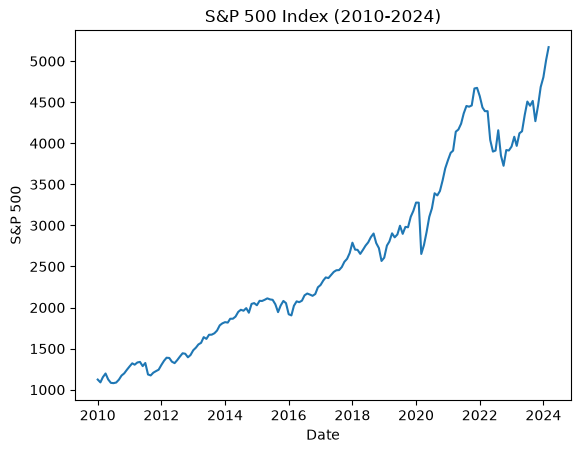

In [41]:
import matplotlib.pyplot as plt

# line plot of S&P 500
plt.figure()
plt.plot(data["observation_date"], data["SP500"])

plt.title("S&P 500 Index (2010-2024)")
plt.xlabel("Date")
plt.ylabel("S&P 500")

plt.show()

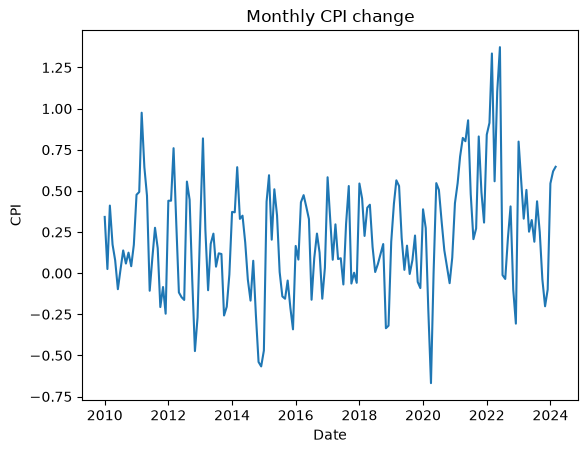

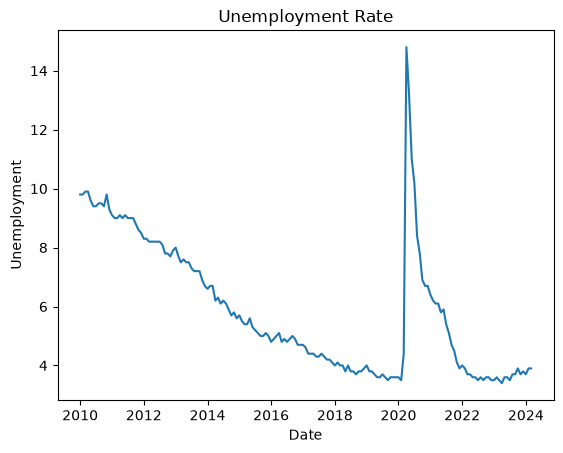

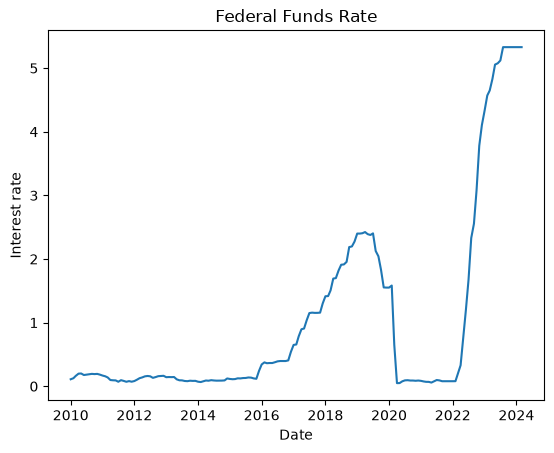

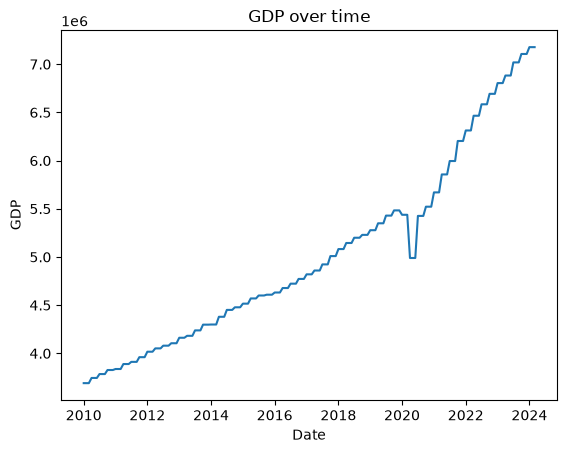

In [42]:
# separate plots for each economic indicator
plt.figure()
plt.plot(data["observation_date"], data["CPI"])
plt.title("Monthly CPI change")
plt.xlabel("Date")
plt.ylabel("CPI")
plt.show()

plt.figure()
plt.plot(data["observation_date"], data["Unemployment"])
plt.title("Unemployment Rate")
plt.xlabel("Date")
plt.ylabel("Unemployment")
plt.show()

plt.figure()
plt.plot(data["observation_date"], data["Interest_Rate"])
plt.title("Federal Funds Rate")
plt.xlabel("Date")
plt.ylabel("Interest rate")
plt.show()

plt.figure()
plt.plot(data["observation_date"], data["GDP"])
plt.title("GDP over time")
plt.xlabel("Date")
plt.ylabel("GDP")
plt.show()